# Migrating from Prophet to skforecast

[Prophet](https://github.com/facebook/prophet) made forecasting accessible to many Python users: one model with trend, seasonality and holidays, fitted in a few lines. As of version 1.4.0, Prophet is in maintenance mode: it accepts bug fixes and dependency updates, but no new features are planned.

This guide is for users who have Prophet code, or follow tutorials based on it, and want to try skforecast. It covers:

+ How each Prophet concept translates to skforecast.

+ Two side-by-side backtests with the same folds for both libraries: the daily series of Prophet's own quick start, and an hourly series with exogenous variables.

+ When Prophet is still a reasonable choice and what skforecast adds.

## Prophet concepts in skforecast

| Prophet | skforecast |
|:--------|:-----------|
| DataFrame with `ds` and `y` columns | pandas Series with a `DatetimeIndex` and a frequency |
| `Prophet()` and `fit(df)` | `ForecasterRecursive(estimator, lags)` and `fit(y, exog)` |
| `make_future_dataframe(periods=h)` and `predict(future)` | `predict(steps=h)`: future dates are created internally |
| Trend (piecewise linear with changepoints) | Autoregressive lags follow the level of the series; `differentiation=1` for series with a strong trend |
| `yearly_seasonality`, `weekly_seasonality`, `add_seasonality(fourier_order=...)` | Fourier terms as exogenous variables, or `calendar_features=CalendarFeatures(...)`, plus seasonal lags (for example 7 or 168) |
| `add_seasonality(condition_name=...)` | Tree-based models learn the interactions between calendar features and exogenous variables |
| `holidays` table with `lower_window` and `upper_window` | Binary columns in `exog` that cover the same days, or `calculate_distance_from_holiday` |
| `add_regressor(name)` | A column in `exog` |
| `interval_width=0.8` (`yhat_lower`, `yhat_upper`) | `predict_interval(steps, interval=[0.1, 0.9])` |
| `cross_validation(model, initial, period, horizon)` | `backtesting_forecaster(forecaster, y, cv=TimeSeriesFold(initial_train_size, steps, refit))` |
| `performance_metrics(df_cv)` | `metric` argument of `backtesting_forecaster` |
| `growth='logistic'` with `cap` and `floor` | No direct equivalent; to keep predictions within bounds, transform the series with `transformer_y` |

The estimator can be any scikit-learn compatible regressor: a linear model such as `Ridge` is the closest translation of Prophet (a linear model of trend, Fourier terms and holidays), while gradient boosting models such as LightGBM capture non-linear effects and interactions.

## Libraries

In [1]:
# Libraries
# ==============================================================================
import time
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm
from lightgbm import LGBMRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
import prophet
from prophet import Prophet
from prophet.diagnostics import cross_validation
import skforecast
from skforecast.datasets import fetch_dataset
from skforecast.recursive import ForecasterRecursive, ForecasterEquivalentDate
from skforecast.preprocessing import CalendarFeatures
from skforecast.model_selection import TimeSeriesFold, backtesting_forecaster
from skforecast.plot import set_dark_theme

logging.getLogger('cmdstanpy').disabled = True
logging.getLogger('prophet').setLevel(logging.WARNING)

print(f"prophet version    : {prophet.__version__}")
print(f"skforecast version : {skforecast.__version__}")
print(f"lightgbm version   : {lightgbm.__version__}")

prophet version    : 1.5.0
skforecast version : 0.26.0
lightgbm version   : 4.7.0


## Case 1: daily series with yearly seasonality

The series is the log of the daily views of the Wikipedia page of Peyton Manning, the dataset of [Prophet's quick start](https://facebook.github.io/prophet/docs/quick_start.html). It has a strong yearly seasonality (the NFL season) and peaks during the playoffs and the Super Bowl.

Prophet ignores the dates without data, while skforecast needs a complete index. To compare both libraries on the same data, the missing values are interpolated.

╭──────────────────────────────── wikipedia_visits ────────────────────────────────╮
│ Description:                                                                     │
│ Log daily page views for the Wikipedia page for Peyton Manning. Scraped data     │
│ using the Wikipediatrend package in R.                                           │
│                                                                                  │
│ Source:                                                                          │
│ https://github.com/facebook/prophet/blob/main/examples/example_wp_log_peyton_man │
│ ning.csv                                                                         │
│                                                                                  │
│ URL:                                                                             │
│ https://raw.githubusercontent.com/skforecast/skforecast-                         │
│ datasets/main/data/wikipedia_visits.csv                                          │
│                                                                                  │
│ Shape: 2964 rows x 1 columns                                                     │
╰──────────────────────────────────────────────────────────────────────────────────╯

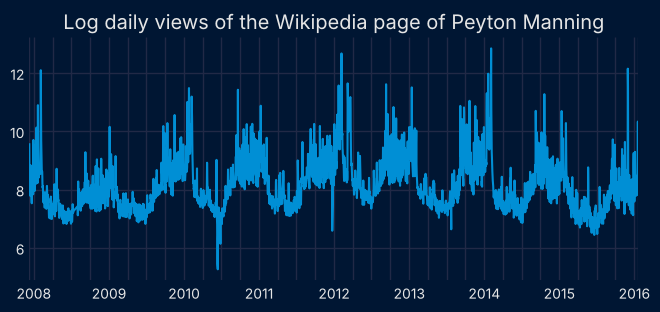

In [2]:
# Data
# ==============================================================================
data = fetch_dataset('wikipedia_visits')
data['y'] = data['y'].interpolate()

# Plot
# ==============================================================================
set_dark_theme()
fig, ax = plt.subplots(figsize=(7, 3))
data['y'].plot(ax=ax)
ax.set_title('Log daily views of the Wikipedia page of Peyton Manning')
ax.set_xlabel('');

### Holidays

Prophet takes a table of holidays with a window of days around each one. In skforecast, holidays are exogenous variables: one binary column per type of holiday that marks the same days. The playoff and Super Bowl dates are those of [Prophet's documentation](https://facebook.github.io/prophet/docs/seasonality,_holiday_effects,_and_regressors.html), with `upper_window=1` (the game day and the day after).

In [3]:
# Holidays: Prophet table and skforecast exogenous variables
# ==============================================================================
playoffs = pd.to_datetime([
    '2008-01-13', '2009-01-03', '2010-01-16', '2010-01-24', '2010-02-07',
    '2011-01-08', '2013-01-12', '2014-01-12', '2014-01-19', '2014-02-02',
    '2015-01-11', '2016-01-17', '2016-01-24', '2016-02-07'
])
superbowls = pd.to_datetime(['2010-02-07', '2014-02-02', '2016-02-07'])

holidays = pd.concat([
    pd.DataFrame({'holiday': 'playoff', 'ds': playoffs, 'lower_window': 0, 'upper_window': 1}),
    pd.DataFrame({'holiday': 'superbowl', 'ds': superbowls, 'lower_window': 0, 'upper_window': 1}),
])

exog = pd.DataFrame(index=data.index)
exog['playoff'] = data.index.isin(playoffs.union(playoffs.shift(1, freq='D'))).astype(int)
exog['superbowl'] = data.index.isin(superbowls.union(superbowls.shift(1, freq='D'))).astype(int)

### Seasonality

By default, Prophet models the yearly seasonality with 10 pairs of Fourier terms and the weekly seasonality with 3. The same terms, added as exogenous variables, give a linear model the same seasonal shapes. For a single pair of terms per feature (or for tree-based models), `CalendarFeatures` creates them from the index without building `exog` (see Case 2).

In [4]:
# Fourier terms with the same periods and orders as Prophet's defaults
# ==============================================================================
t = (data.index - pd.Timestamp('1970-01-01')).days.to_numpy()
for name, period, order in [('yearly', 365.25, 10), ('weekly', 7, 3)]:
    for k in range(1, order + 1):
        exog[f'{name}_sin_{k}'] = np.sin(2 * np.pi * k * t / period)
        exog[f'{name}_cos_{k}'] = np.cos(2 * np.pi * k * t / period)

exog.head(3)

,playoff,superbowl,yearly_sin_1,yearly_cos_1,yearly_sin_2,yearly_cos_2,yearly_sin_3,yearly_cos_3,yearly_sin_4,yearly_cos_4,...,yearly_sin_9,yearly_cos_9,yearly_sin_10,yearly_cos_10,weekly_sin_1,weekly_cos_1,weekly_sin_2,weekly_cos_2,weekly_sin_3,weekly_cos_3
date,,,,,,,,,,,,,,,,,,,,,
2007-12-10,0,0,-0.377462,0.926025,-0.699079,0.715044,-0.917267,0.398272,-0.999745,0.022576,...,0.335276,-0.942120,0.666089,-0.745872,-0.433884,-0.900969,0.781831,0.623490,-0.974928,-0.222521
2007-12-11,0,0,-0.361478,0.932381,-0.674069,0.738668,-0.895501,0.445059,-0.995827,0.091261,...,0.185987,-0.982552,0.528581,-0.848883,-0.974928,-0.222521,0.433884,-0.900969,0.781831,0.623490
2007-12-12,0,0,-0.345386,0.938461,-0.648262,0.761418,-0.871351,0.490660,-0.987196,0.159513,...,0.032249,-0.999480,0.375470,-0.926834,-0.781831,0.623490,-0.974928,-0.222521,-0.433884,-0.900969


### Fit and predict

Both models forecast the last 30 days. Prophet needs a DataFrame with the future dates, created with `make_future_dataframe`. skforecast only needs the number of steps (and the exogenous variables of those dates). The forecaster combines the last 14 values of the series (lags) with the holidays and the Fourier terms in a `Ridge` regression.

In [5]:
# Prophet: fit and predict the last 30 days
# ==============================================================================
steps = 30
df = data.reset_index().rename(columns={'date': 'ds'})

model = Prophet(holidays=holidays)
model.fit(df.iloc[:-steps])
future = model.make_future_dataframe(periods=steps)
forecast = model.predict(future)
predictions_prophet = forecast.set_index('ds')[['yhat', 'yhat_lower', 'yhat_upper']].iloc[-steps:]
predictions_prophet.head(3)

,yhat,yhat_lower,yhat_upper
ds,,,
2015-12-22,8.080191,7.419937,8.678470
2015-12-23,7.904629,7.328505,8.464103
2015-12-24,7.904908,7.275170,8.490877


In [6]:
# skforecast: fit and predict the last 30 days
# ==============================================================================
forecaster = ForecasterRecursive(estimator=Ridge(), lags=14)
forecaster.fit(
    y                         = data['y'].iloc[:-steps],
    exog                      = exog.iloc[:-steps],
    store_in_sample_residuals = True
)
predictions = forecaster.predict_interval(
                  steps    = steps,
                  exog     = exog.iloc[-steps:],
                  interval = [0.1, 0.9]
              )
predictions.head(3)

,pred,lower_bound,upper_bound
2015-12-22,8.167202,7.806039,8.487544
2015-12-23,7.964266,7.585161,8.234653
2015-12-24,7.969479,7.545609,8.304264


Both libraries return an 80% prediction interval. In skforecast, its coverage depends on the residuals used to build it; the [probabilistic forecasting guides](probabilistic-forecasting-overview.html) explain how to calibrate it.

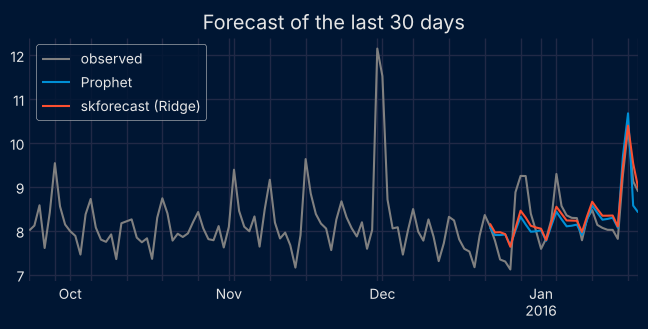

In [7]:
# Plot predictions
# ==============================================================================
fig, ax = plt.subplots(figsize=(7, 3))
data['y'].iloc[-120:].plot(ax=ax, label='observed', color='gray')
predictions_prophet['yhat'].plot(ax=ax, label='Prophet')
predictions['pred'].plot(ax=ax, label='skforecast (Ridge)')
ax.set_title('Forecast of the last 30 days')
ax.set_xlabel('')
ax.legend();

### Backtesting with the same folds

Prophet's `cross_validation` and skforecast's `backtesting_forecaster` do the same: they refit the model at each cutoff and forecast the next `horizon` (`steps`) periods. To compare both libraries on exactly the same folds, the cutoffs passed to Prophet are the last training dates of the folds of `TimeSeriesFold`: 24 folds of 30 days over the last two years, with an expanding training window (`fixed_train_size=False`), as Prophet does.

In [8]:
# Folds shared by both libraries
# ==============================================================================
cv = TimeSeriesFold(
         steps              = 30,
         initial_train_size = len(data) - 720,
         refit              = True,
         fixed_train_size   = False,
         verbose            = False
     )

# Prophet cutoffs: the last training date of each fold of `cv`
cutoffs = pd.date_range(end=data.index[-31], periods=24, freq='30D')
print(f"Number of folds : {len(cutoffs)}")
print(f"First cutoff    : {cutoffs[0].date()}")
print(f"Last cutoff     : {cutoffs[-1].date()}")

Number of folds : 24
First cutoff    : 2014-01-30
Last cutoff     : 2015-12-21


In [9]:
# Prophet: cross-validation
# ==============================================================================
model = Prophet(holidays=holidays).fit(df)

start = time.perf_counter()
cv_prophet = cross_validation(model, cutoffs=list(cutoffs), horizon='30 days', disable_tqdm=True)
time_prophet = time.perf_counter() - start

In [10]:
# skforecast: backtesting of the Ridge forecaster and of a baseline
# ==============================================================================
start = time.perf_counter()
metric_ridge, predictions_ridge = backtesting_forecaster(
                                      forecaster    = ForecasterRecursive(estimator=Ridge(), lags=14),
                                      y             = data['y'],
                                      exog          = exog,
                                      cv            = cv,
                                      metric        = 'mean_absolute_error',
                                      show_progress = False
                                  )
time_ridge = time.perf_counter() - start

# Baseline: the value of the same day of the previous week
metric_baseline, _ = backtesting_forecaster(
                         forecaster    = ForecasterEquivalentDate(offset=pd.DateOffset(days=7)),
                         y             = data['y'],
                         cv            = cv,
                         metric        = 'mean_absolute_error',
                         show_progress = False
                     )

In [11]:
# Results
# ==============================================================================
results = pd.DataFrame({
    'model': ['Prophet', 'skforecast (Ridge)', 'Baseline (same day of the previous week)'],
    'mae': [
        mean_absolute_error(cv_prophet['y'], cv_prophet['yhat']),
        metric_ridge.at[0, 'mean_absolute_error'],
        metric_baseline.at[0, 'mean_absolute_error'],
    ],
    'time (s)': [time_prophet, time_ridge, np.nan],
})
results.round(3)

,model,mae,time (s)
0,Prophet,0.333,21.752
1,skforecast (Ridge),0.348,0.190
2,Baseline (same day of the previous week),0.481,NaN


On Prophet's own quick start series, Prophet has the lowest error: its MAE is about 4% lower than that of the Ridge forecaster, and both are well ahead of the baseline. This is the kind of series Prophet was designed for: daily, with a strong and stable yearly seasonality and known events. The skforecast model, a direct translation of Prophet's components plus lags, runs the 24 folds more than 100 times faster.

## Case 2: hourly series with exogenous variables

The series is the hourly number of users of the bike sharing system of Washington D.C. (2011 and 2012), with the weather and the type of day as exogenous variables. The daily pattern of a working day (two commuting peaks) differs from that of a weekend or holiday.

Both models forecast the next 7 days (168 hours) in 8 folds over the last 8 weeks. Both receive the observed weather of the forecast horizon; in production, weather forecasts would add error to both.

In [12]:
# Data
# ==============================================================================
data_bike = fetch_dataset('bike_sharing')
exog_cols = ['temp', 'hum', 'windspeed', 'holiday', 'workingday']
y_bike = data_bike['users']
exog_bike = data_bike[exog_cols]

# Folds shared by both libraries
# ==============================================================================
cv_bike = TimeSeriesFold(
              steps              = 168,
              initial_train_size = len(data_bike) - 168 * 8,
              refit              = True,
              fixed_train_size   = False,
              verbose            = False
          )

# Prophet cutoffs: the last training date of each fold of `cv_bike`
cutoffs_bike = pd.date_range(end=data_bike.index[-169], periods=8, freq='168h')

╭───────────────────────────────── bike_sharing ──────────────────────────────────╮
│ Description:                                                                    │
│ Hourly usage of the bike share system in the city of Washington D.C. during the │
│ years 2011 and 2012. In addition to the number of users per hour, information   │
│ about weather conditions and holidays is available.                             │
│                                                                                 │
│ Source:                                                                         │
│ Fanaee-T,Hadi. (2013). Bike Sharing Dataset. UCI Machine Learning Repository.   │
│ https://doi.org/10.24432/C5W894.                                                │
│                                                                                 │
│ URL:                                                                            │
│ https://raw.githubusercontent.com/skforecast/skforecast-                        │
│ datasets/main/data/bike_sharing_dataset_clean.csv                               │
│                                                                                 │
│ Shape: 17544 rows x 11 columns                                                  │
╰─────────────────────────────────────────────────────────────────────────────────╯

For Prophet, the configuration follows its documentation: weather and type of day with `add_regressor`, and a [conditional daily seasonality](https://facebook.github.io/prophet/docs/seasonality,_holiday_effects,_and_regressors.html#seasonalities-that-depend-on-other-factors), one for working days and another for the rest, so that each type of day has its own daily pattern. The Fourier order of these seasonalities (6) is higher than the default of the daily seasonality (4) to capture the two commuting peaks.

In [13]:
# Prophet: regressors and conditional daily seasonality
# ==============================================================================
df_bike = (
    data_bike[['users'] + exog_cols]
    .reset_index()
    .rename(columns={'date_time': 'ds', 'users': 'y'})
)
df_bike['workday'] = df_bike['workingday'] == 1
df_bike['offday'] = ~df_bike['workday']

model = Prophet(daily_seasonality=False)
model.add_seasonality(name='daily_workday', period=1, fourier_order=6, condition_name='workday')
model.add_seasonality(name='daily_offday', period=1, fourier_order=6, condition_name='offday')
for col in exog_cols:
    model.add_regressor(col)
model.fit(df_bike)

start = time.perf_counter()
cv_prophet_bike = cross_validation(
                      model, cutoffs=list(cutoffs_bike), horizon='168 hours', disable_tqdm=True
                  )
time_prophet_bike = time.perf_counter() - start

In skforecast, a LightGBM model with lags of the previous hours, the same hours of the previous day and of the previous week, the calendar features (hour, day of the week and month) and the same exogenous variables. The trees learn by themselves that the effect of the hour depends on the type of day.

In [14]:
# skforecast: LightGBM with lags, calendar features and exogenous variables
# ==============================================================================
forecaster = ForecasterRecursive(
                 estimator         = LGBMRegressor(random_state=123, verbose=-1),
                 lags              = [1, 2, 3, 23, 24, 25, 167, 168, 169],
                 calendar_features = CalendarFeatures(
                                         features = ['hour', 'day_of_week', 'month'],
                                         encoding = None
                                     )
             )

start = time.perf_counter()
metric_lgbm, predictions_lgbm = backtesting_forecaster(
                                    forecaster    = forecaster,
                                    y             = y_bike,
                                    exog          = exog_bike,
                                    cv            = cv_bike,
                                    metric        = 'mean_absolute_error',
                                    show_progress = False
                                )
time_lgbm = time.perf_counter() - start

# Baseline: the value of the same hour of the previous week
metric_baseline_bike, _ = backtesting_forecaster(
                              forecaster    = ForecasterEquivalentDate(offset=pd.DateOffset(days=7)),
                              y             = y_bike,
                              cv            = cv_bike,
                              metric        = 'mean_absolute_error',
                              show_progress = False
                          )

In [15]:
# Results
# ==============================================================================
results_bike = pd.DataFrame({
    'model': ['Prophet', 'skforecast (LightGBM)', 'Baseline (same hour of the previous week)'],
    'mae': [
        mean_absolute_error(cv_prophet_bike['y'], cv_prophet_bike['yhat']),
        metric_lgbm.at[0, 'mean_absolute_error'],
        metric_baseline_bike.at[0, 'mean_absolute_error'],
    ],
    'time (s)': [time_prophet_bike, time_lgbm, np.nan],
})
results_bike.round(1)

,model,mae,time (s)
0,Prophet,61.9,92.8
1,skforecast (LightGBM),56.8,1.7
2,Baseline (same hour of the previous week),72.6,NaN


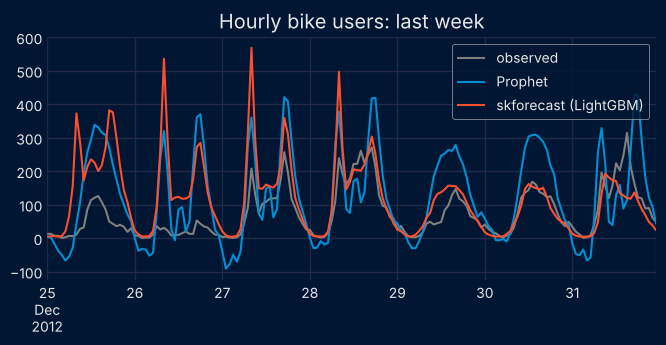

In [16]:
# Plot predictions of the last fold
# ==============================================================================
fig, ax = plt.subplots(figsize=(7, 3))
y_bike.iloc[-168:].plot(ax=ax, label='observed', color='gray')
cv_prophet_bike.set_index('ds')['yhat'].iloc[-168:].plot(ax=ax, label='Prophet')
predictions_lgbm['pred'].iloc[-168:].plot(ax=ax, label='skforecast (LightGBM)')
ax.set_title('Hourly bike users: last week')
ax.set_xlabel('')
ax.legend();

On this series, the LightGBM forecaster has an error about 8% lower than that of Prophet and runs the 8 folds about 50 times faster, without having to specify which seasonalities depend on the type of day. The plot also shows a limitation of an additive model: Prophet predicts a negative number of users at night, which the LightGBM forecaster does not do in that week.

Neither model was tuned beyond the configuration shown, and two series are not a general benchmark: the point is that the best option depends on the series, and backtesting both on the same folds is how to choose.

## When to keep Prophet and what skforecast adds

Prophet is still a reasonable choice for a single daily or weekly series with a strong and stable seasonality and known events (as in Case 1), especially when the forecast has to be explained as the sum of a trend, seasonalities and holiday effects.

skforecast adds the most when:

+ The series depends on exogenous variables or on interactions between patterns (as in Case 2): any scikit-learn compatible regressor, such as LightGBM, learns them from the data.

+ There are many series: a [global model](global-forecasting-overview.html) learns from all of them at once, instead of one Prophet model per series.

+ Models have to be refitted many times, in backtesting, hyperparameter search or production: training is much faster.

+ You want to compare model families with the same API and the same backtesting: machine learning, statistical models (ARIMA, ETS) and foundation models that forecast without training.

## Next steps

+ [Calendar features](calendar-features.html) and [exogenous variables](exogenous-variables.html): the skforecast counterparts of seasonalities, holidays and regressors.

+ [Backtesting](backtesting.html): all the options of `TimeSeriesFold`, such as gaps, fixed training windows or refitting every *n* folds.

+ [Probabilistic forecasting](probabilistic-forecasting-overview.html): bootstrapping, conformal prediction and quantile regression.

+ [Global forecasting](global-forecasting-overview.html): one model for many series, instead of one Prophet model per series.

+ [Statistical models](forecasting-statistical-models.html) and [foundation models](foundation-forecasting-models.html): ARIMA, ETS and zero-shot pretrained models with the same API.